# EDA 01 · Members (demographics)

**Question.** What signal does the customer profile carry, and how should each field be encoded?

**Fields.** `members_v3`: `city`, `bd` (age), `gender`, `registered_via`, `registration_init_time`.

**Population.** `fit` part of the February cohort (744,699 customers; see notebook 00). 86,709 of them (11.6 %) have no member record.

**Method.** Churn rate per level with Wilson 95 % intervals; confounding checked with cross tables; candidate encodings compared with 5-fold cross-validated ROC AUC and log-loss inside `fit`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

pl.Config.set_tbl_rows(40)
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.max_colwidth", None)

users = C.load_fit_population()
BASE = users["is_churn"].mean()
members = C.scan_members(users).collect()
df = users.join(members, on="msno", how="left")
print(f"fit customers: {users.height:,} | with member record: {members.height:,} (one row each: {members['msno'].n_unique() == members.height})")

fit customers: 744,699 | with member record: 657,990 (one row each: True)


## 1. Field inventory

In [2]:
m = df.filter(pl.col("city").is_not_null())
pd.DataFrame({
    "field": ["city", "bd", "gender", "registered_via", "registration_init_time"],
    "distinct": [m["city"].n_unique(), m["bd"].n_unique(), m["gender"].n_unique(),
                 m["registered_via"].n_unique(), m["registration_init_time"].n_unique()],
    "min": [m["city"].min(), m["bd"].min(), None, m["registered_via"].min(), m["registration_init_time"].min()],
    "max": [m["city"].max(), m["bd"].max(), None, m["registered_via"].max(), m["registration_init_time"].max()],
    "null share (member rows)": [m[c].null_count() / m.height for c in
                                  ("city", "bd", "gender", "registered_via", "registration_init_time")],
})

,field,distinct,min,max,null share (member rows)
0,city,21,1.0000,22.0000,0.0000
1,bd,213,"-3,152.0000","1,820.0000",0.0000
2,gender,3,NaN,NaN,0.5530
3,registered_via,5,3.0000,13.0000,0.0000
4,registration_init_time,4720,"20,040,326.0000","20,170,330.0000",0.0000


In [3]:
print("bd == 0:", f"{(m['bd'] == 0).mean():.2%}",
      "| bd outside 1..100 (non-zero):", f"{((m['bd'] != 0) & ~m['bd'].is_between(1, 100)).sum():,}")
print("registered_via levels:", sorted(m["registered_via"].unique().to_list()))

bd == 0: 55.53% | bd outside 1..100 (non-zero): 403
registered_via levels: [3, 4, 7, 9, 13]


- `registered_via` has only **five levels** in this population (3, 4, 7, 9, 13) and **no negative values**, so the current "negative → mode" cleaning rule never fires.
- `bd = 0` is the dominant value: it is how a missing age is stored. Truly invalid ages (negative or above 100) are a few hundred rows.
- `gender` is null on the same rows where `bd = 0`, which section 2 makes precise.

## 2. Missing profile: one phenomenon, not three

Cross table of the age state and the gender state.

In [4]:
df = df.with_columns(
    bd_state=pl.when(pl.col("city").is_null()).then(pl.lit("no member"))
    .when(pl.col("bd") == 0).then(pl.lit("zero"))
    .when(pl.col("bd").is_between(1, 100)).then(pl.lit("valid"))
    .otherwise(pl.lit("invalid")),
    gender_state=pl.when(pl.col("city").is_null()).then(pl.lit("no member"))
    .when(pl.col("gender").is_null()).then(pl.lit("null"))
    .otherwise(pl.col("gender")),
)
C.churn_rate_by(df, ["bd_state", "gender_state"]).sort_values("n", ascending=False)[
    ["bd_state", "gender_state", "n", "share", "churn_rate"]].reset_index(drop=True)

,bd_state,gender_state,n,share,churn_rate
0,zero,null,356826,0.4792,0.0466
1,valid,male,150766,0.2025,0.0885
2,valid,female,134481,0.1806,0.0860
3,no member,no member,86709,0.1164,0.0505
4,valid,null,6971,0.0094,0.1333
5,zero,female,4694,0.0063,0.0831
6,zero,male,3849,0.0052,0.0870
7,invalid,male,213,0.0003,0.1408
8,invalid,female,123,0.0002,0.1057
9,invalid,null,67,0.0001,0.0149


In [5]:
df = df.with_columns(profile_state=
    pl.when(pl.col("city").is_null()).then(pl.lit("no member"))
    .when(~pl.col("bd").is_between(1, 100) & pl.col("gender").is_null()).then(pl.lit("incomplete"))
    .otherwise(pl.lit("complete")))
(df.filter(pl.col("profile_state") != "no member")
   .group_by("profile_state")
   .agg(n=pl.len(), city_is_1=(pl.col("city") == 1).mean(), churn=pl.col("is_churn").mean()))

profile_state,n,city_is_1,churn
str,u32,f64,f64
"""complete""",301097,0.036636,0.088354
"""incomplete""",356893,0.926171,0.046571


- `bd = 0` and `gender = null` occur together for 356,826 customers (48 % of `fit`). Only about 15k rows have one without the other.
- **`city = 1` is the default value of an empty profile**: 93 % of incomplete profiles have `city = 1`, against 3.7 % of complete ones. Treating `city = 1` as a real city mixes geography with "the customer never filled the form".
- Definition used from here on: **`profile_state`** = `no member` / `incomplete` (no valid age **and** no gender) / `complete`.

At first sight incomplete profiles churn far less (4.7 % vs 8.8 %). Section 6 shows that most of this gap is the registration channel.

## 3. Age (valid values only)

Churn rate per year of age, for ages with at least 500 customers.

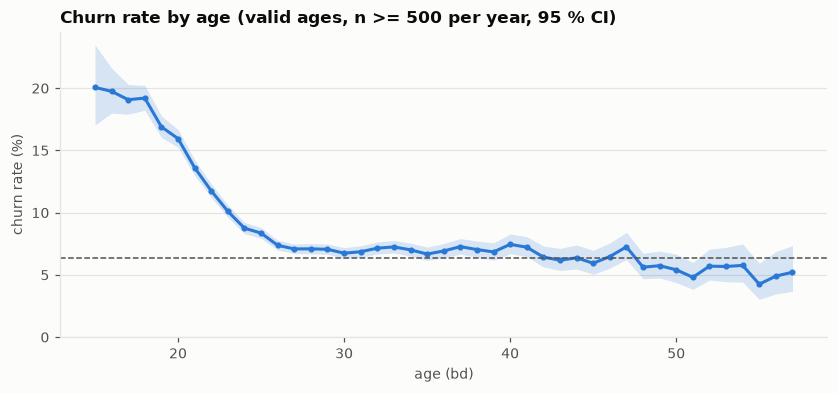

,0,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
bd,15.0000,16.0000,17.0000,18.0000,19.0000,20.0000,21.0000,22.0000,23.0000,24.0000,...,48.0000,49.0000,50.0000,51.0000,52.0000,53.0000,54.0000,55.0000,56.0000,57.0000
n,593.0000,"1,858.0000","4,162.0000","6,007.0000","7,244.0000","10,159.0000","11,670.0000","13,566.0000","14,450.0000","15,393.0000",...,"1,956.0000","1,794.0000","1,533.0000","1,519.0000","1,350.0000","1,092.0000",902.0000,752.0000,632.0000,575.0000
rate,0.2007,0.1975,0.1908,0.1921,0.1690,0.1596,0.1362,0.1176,0.1011,0.0876,...,0.0562,0.0574,0.0541,0.0481,0.0570,0.0568,0.0576,0.0426,0.0491,0.0522


In [6]:
age = (df.filter(pl.col("bd").is_between(1, 100))
       .group_by("bd").agg(n=pl.len(), churners=pl.col("is_churn").sum())
       .filter(pl.col("n") >= 500).sort("bd").to_pandas())
age["rate"] = age["churners"] / age["n"]
age["lo"], age["hi"] = C.wilson(age["churners"], age["n"])

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.fill_between(age["bd"], age["lo"] * 100, age["hi"] * 100, color=C.COLORS["series"], alpha=0.18, linewidth=0)
ax.plot(age["bd"], age["rate"] * 100, color=C.COLORS["series"], linewidth=2, marker="o", markersize=3)
ax.axhline(BASE * 100, color=C.COLORS["base"], linestyle="--", linewidth=1)
ax.set_xlabel("age (bd)"); ax.set_ylabel("churn rate (%)"); ax.set_ylim(0, None)
ax.set_title("Churn rate by age (valid ages, n >= 500 per year, 95 % CI)", loc="left")
C.save_fig(fig, "01_age_curve"); plt.show()
age[["bd", "n", "rate"]].T

The shape is a **threshold, not a line**: churn falls from about 20 % at 16–18 to about 7 % at 26, stays flat around 7 % up to the mid-40s, and drifts to about 5.5 % in the 50s. The signal is concentrated in the youngest customers. Bands that follow this curve:

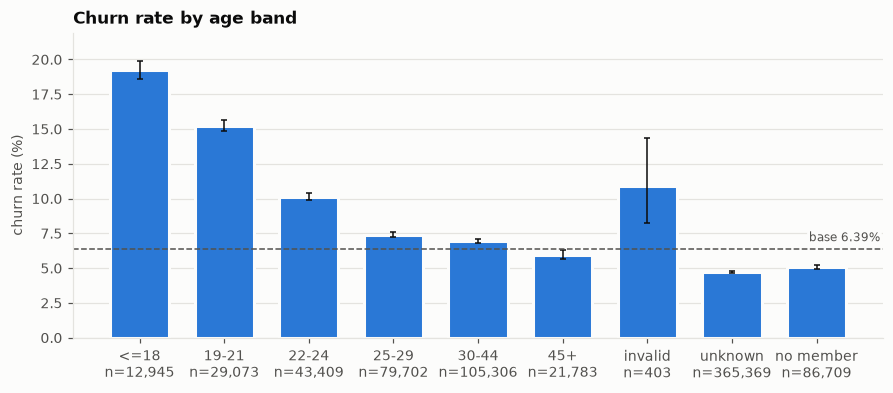

,age_band,n,churners,churn_rate,ci_low,ci_high,share,lift
0,<=18,12945,2490,0.1924,0.1857,0.1992,0.0174,3.0091
1,19-21,29073,4434,0.1525,0.1484,0.1567,0.0390,2.3859
2,22-24,43409,4404,0.1015,0.0986,0.1043,0.0583,1.5871
3,25-29,79702,5894,0.0740,0.0722,0.0758,0.1070,1.1569
4,30-44,105306,7316,0.0695,0.0680,0.0710,0.1414,1.0868
5,45+,21783,1297,0.0595,0.0565,0.0628,0.0293,0.9315
6,invalid,403,44,0.1092,0.0823,0.1434,0.0005,1.7080
7,unknown,365369,17345,0.0475,0.0468,0.0482,0.4906,0.7426
8,no member,86709,4380,0.0505,0.0491,0.0520,0.1164,0.7902


In [7]:
AGE_ORDER = ["<=18", "19-21", "22-24", "25-29", "30-44", "45+", "invalid", "unknown", "no member"]
df = df.with_columns(age_band=
    pl.when(pl.col("city").is_null()).then(pl.lit("no member"))
    .when(pl.col("bd") == 0).then(pl.lit("unknown"))
    .when(~pl.col("bd").is_between(1, 100)).then(pl.lit("invalid"))
    .when(pl.col("bd") <= 18).then(pl.lit("<=18"))
    .when(pl.col("bd") <= 21).then(pl.lit("19-21"))
    .when(pl.col("bd") <= 24).then(pl.lit("22-24"))
    .when(pl.col("bd") <= 29).then(pl.lit("25-29"))
    .when(pl.col("bd") <= 44).then(pl.lit("30-44"))
    .otherwise(pl.lit("45+")))
age_table = C.churn_rate_by(df, "age_band", order=AGE_ORDER)
fig, ax = plt.subplots(figsize=(9.5, 3.6))
C.plot_churn_rate(age_table, "age_band", ax=ax, base_rate=BASE, title="Churn rate by age band")
C.save_fig(fig, "01_age_band"); plt.show()
age_table

### 3.1 Which age encoding?

Three candidates, each evaluated alone and next to `registered_via` (5-fold stratified CV inside `fit`):

| Encoding | Model | Description |
|---|---|---|
| A · mean + flag (current w1) | logistic | invalid/missing age → train mean, plus `bd_missing` |
| B · bands | logistic | one-hot of `age_band` (unknown, invalid and no member are their own levels) |
| C · raw + NaN | gradient boosting | `bd` with missing as NaN: a flexible upper bound for what age can give |

In [8]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=C.SEED)
y = df["is_churn"].to_numpy()
valid = df["bd"].is_between(1, 100).fill_null(False)
age_mean = df.filter(valid)["bd"].mean()
X = df.with_columns(
    bd_mean=pl.when(valid).then(pl.col("bd")).otherwise(age_mean).cast(pl.Float64),
    bd_missing=(~valid).cast(pl.Int8),
    bd_nan=pl.when(valid).then(pl.col("bd")).otherwise(None).cast(pl.Float64),
    via=pl.col("registered_via").cast(pl.String).fill_null("no member"),
).select("bd_mean", "bd_missing", "bd_nan", "age_band", "via").to_pandas()

def logit(num=(), cat=()):
    pre = ColumnTransformer([("num", StandardScaler(), list(num)),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), list(cat))])
    return make_pipeline(pre, LogisticRegression(max_iter=2000))

def gbm(cols, cat_cols=()):
    pre = ColumnTransformer([("pass", "passthrough", [c for c in cols if c not in cat_cols]),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat_cols))])
    return make_pipeline(pre, HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, random_state=C.SEED))

def cv(model, cols):
    s = cross_validate(model, X[list(cols)], y, cv=CV, scoring=("roc_auc", "neg_log_loss"), n_jobs=5)
    return {"roc_auc": s["test_roc_auc"].mean(), "roc_auc_sd": s["test_roc_auc"].std(),
            "log_loss": -s["test_neg_log_loss"].mean()}

prior_ll = -(BASE * np.log(BASE) + (1 - BASE) * np.log(1 - BASE))
runs = {
    "A mean+flag":          (logit(num=["bd_mean", "bd_missing"]), ["bd_mean", "bd_missing"]),
    "B bands":              (logit(cat=["age_band"]), ["age_band"]),
    "C raw+NaN (GBM)":      (gbm(["bd_nan"]), ["bd_nan"]),
    "via only":             (logit(cat=["via"]), ["via"]),
    "A mean+flag + via":    (logit(num=["bd_mean", "bd_missing"], cat=["via"]), ["bd_mean", "bd_missing", "via"]),
    "B bands + via":        (logit(cat=["age_band", "via"]), ["age_band", "via"]),
    "C raw+NaN + via (GBM)": (gbm(["bd_nan", "via"], cat_cols=["via"]), ["bd_nan", "via"]),
}
enc = pd.DataFrame({k: cv(*v) for k, v in runs.items()}).T
enc["log_loss_gain_vs_prior"] = prior_ll - enc["log_loss"]
enc

,roc_auc,roc_auc_sd,log_loss,log_loss_gain_vs_prior
A mean+flag,0.5978,0.0023,0.2330,0.0046
B bands,0.6019,0.0041,0.2320,0.0056
C raw+NaN (GBM),0.6000,0.0036,0.2320,0.0056
via only,0.6801,0.0022,0.2241,0.0135
A mean+flag + via,0.6874,0.0020,0.2232,0.0144
B bands + via,0.6903,0.0026,0.2225,0.0152
C raw+NaN + via (GBM),0.6979,0.0019,0.2214,0.0162


## 4. Gender

In [9]:
C.churn_rate_by(df.filter(pl.col("profile_state") == "complete"), "gender_state")[
    ["gender_state", "n", "churn_rate", "ci_low", "ci_high"]]

,gender_state,n,churn_rate,ci_low,ci_high
0,female,139298,0.0860,0.0845,0.0874
1,male,154828,0.0885,0.0871,0.0899
2,null,6971,0.1333,0.1255,0.1414


Among complete profiles, male and female churn at almost the same rate (8.6 % vs 8.9 %). The 2.3 % of complete profiles with a valid age but no gender churn more (13 %), but they are 7k customers and the age band already places most of them. The value of `gender` adds nothing; its **absence** is already carried by `profile_state`.

## 5. Registration channel (`registered_via`)

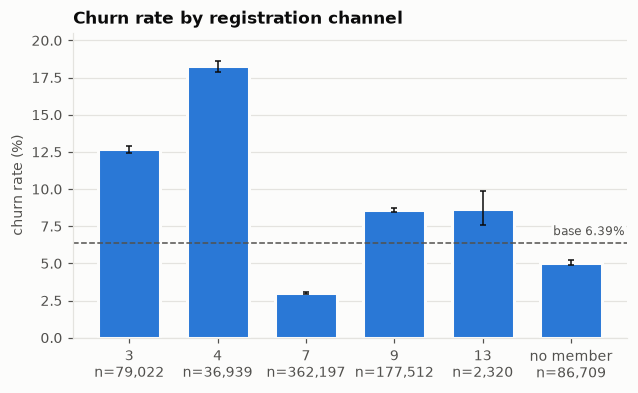

,via,n,churners,churn_rate,ci_low,ci_high,share,lift
0,3,79022,10019,0.1268,0.1245,0.1291,0.1061,1.9834
1,4,36939,6742,0.1825,0.1786,0.1865,0.0496,2.8552
2,7,362197,10968,0.0303,0.0297,0.0308,0.4864,0.4737
3,9,177512,15294,0.0862,0.0849,0.0875,0.2384,1.3478
4,13,2320,201,0.0866,0.0759,0.0988,0.0031,1.3553
5,no member,86709,4380,0.0505,0.0491,0.0520,0.1164,0.7902


In [10]:
VIA_ORDER = ["3", "4", "7", "9", "13", "no member"]
df = df.with_columns(via=pl.col("registered_via").cast(pl.String).fill_null("no member"))
via_table = C.churn_rate_by(df, "via", order=VIA_ORDER)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
C.plot_churn_rate(via_table, "via", ax=ax, base_rate=BASE, title="Churn rate by registration channel")
C.save_fig(fig, "01_registered_via"); plt.show()
via_table

Channel is the strongest demographic signal: from 3.0 % (channel 7, half of the population) to 18 % (channel 4). The legacy EDA said channel 9 churns most; in February channels 4 and 3 do.

## 6. Channel × profile: what explains the low churn of empty profiles?

In [11]:
vp = C.churn_rate_by(df.filter(pl.col("profile_state") != "no member"), ["via", "profile_state"], order=VIA_ORDER)
print("share of incomplete profiles per channel:")
print(df.filter(pl.col("profile_state") != "no member").group_by("via")
        .agg(incomplete_share=(pl.col("profile_state") == "incomplete").mean(), n=pl.len()).sort("via"))
pivot = vp.pivot(index="via", columns="profile_state", values="churn_rate").reindex(VIA_ORDER[:-1])
pivot["n_incomplete"] = vp[vp.profile_state == "incomplete"].set_index("via")["n"]
pivot["n_complete"] = vp[vp.profile_state == "complete"].set_index("via")["n"]
pivot

share of incomplete profiles per channel:
shape: (5, 3)
┌─────┬──────────────────┬────────┐
│ via ┆ incomplete_share ┆ n      │
│ --- ┆ ---              ┆ ---    │
│ str ┆ f64              ┆ u32    │
╞═════╪══════════════════╪════════╡
│ 13  ┆ 0.916379         ┆ 2320   │
│ 3   ┆ 0.1493           ┆ 79022  │
│ 4   ┆ 0.44744          ┆ 36939  │
│ 7   ┆ 0.837409         ┆ 362197 │
│ 9   ┆ 0.130324         ┆ 177512 │
└─────┴──────────────────┴────────┘


profile_state,complete,incomplete,n_incomplete,n_complete
via,,,,
3,0.1254,0.1349,11798,67224
4,0.1808,0.1846,16528,20411
7,0.0429,0.0278,303307,58890
9,0.0773,0.1449,23134,154378
13,0.0876,0.0865,2126,194


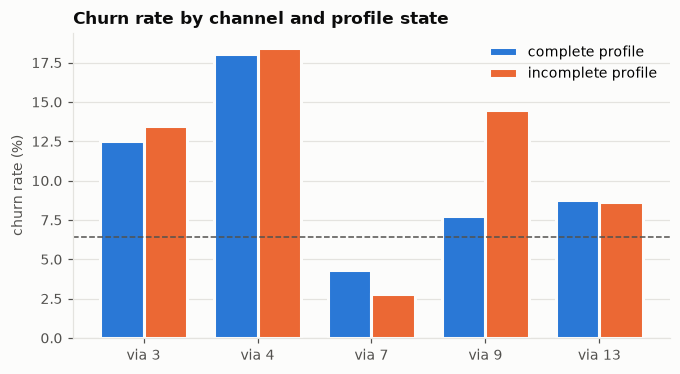

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.6))
w = 0.38
x = np.arange(len(pivot))
for i, (state, color) in enumerate((("complete", C.COLORS["stay"]), ("incomplete", C.COLORS["churn"]))):
    ax.bar(x + (i - 0.5) * w, pivot[state] * 100, width=w, color=color, label=f"{state} profile",
           edgecolor=C.COLORS["surface"], linewidth=2)
ax.axhline(BASE * 100, color=C.COLORS["base"], linestyle="--", linewidth=1)
ax.set_xticks(x, [f"via {v}" for v in pivot.index]); ax.set_ylabel("churn rate (%)")
ax.legend(frameon=False); ax.set_title("Churn rate by channel and profile state", loc="left")
C.save_fig(fig, "01_via_by_profile"); plt.show()

- Channel 7 holds 85 % of the incomplete profiles and is the lowest-churn channel. That composition is most of the raw gap between complete (8.8 %) and incomplete (4.7 %) profiles.
- **Within** channels 3, 4 and 13 the profile state barely matters. In channel 7 incomplete is a little lower (2.8 % vs 4.3 %), and in **channel 9 it goes the other way**: incomplete 14.5 % vs complete 7.7 %.
- So `profile_state` is not a proxy for "safe customer". Its meaning depends on the channel, which is an interaction the linear model only sees if we give it one.

## 7. City

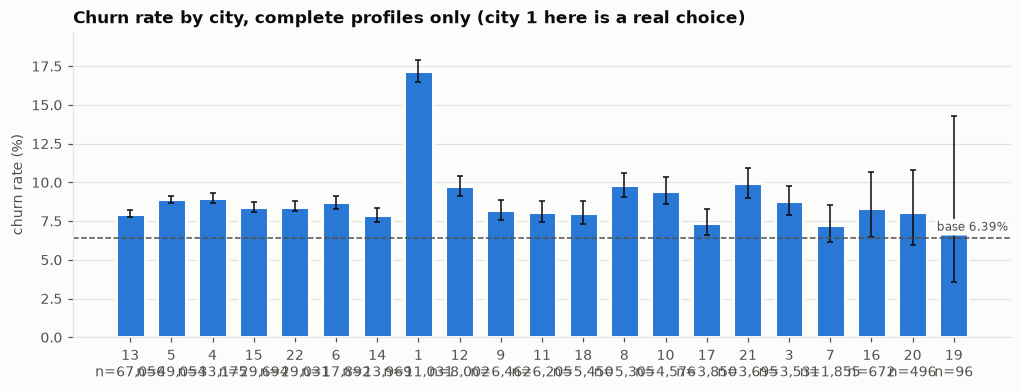

,city_s,n,churn_rate,ci_low,ci_high
0,13,67056,0.0798,0.0778,0.0819
1,5,49054,0.0890,0.0865,0.0915
2,4,33175,0.0899,0.0868,0.0930
3,15,29694,0.0842,0.0811,0.0874
4,22,29031,0.0844,0.0813,0.0877
5,6,17892,0.0870,0.0830,0.0912
6,14,13969,0.0789,0.0745,0.0835
7,1,11031,0.1718,0.1649,0.1789
8,12,8002,0.0974,0.0910,0.1040
9,9,6462,0.0819,0.0754,0.0888


In [13]:
complete = df.filter(pl.col("profile_state") == "complete").with_columns(city_s=pl.col("city").cast(pl.String))
city_table = C.churn_rate_by(complete, "city_s").sort_values("n", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 3.6))
C.plot_churn_rate(city_table, "city_s", ax=ax, base_rate=BASE, rotate=0,
                  title="Churn rate by city, complete profiles only (city 1 here is a real choice)")
C.save_fig(fig, "01_city_complete"); plt.show()
city_table[["city_s", "n", "churn_rate", "ci_low", "ci_high"]]

Among complete profiles every city except city 1 sits in a narrow band around 7–10 %, with overlapping intervals for most of them. City 1 inside complete profiles (about 11k customers) churns at roughly twice that rate; section 9 checks whether city adds anything once channel, profile and age are known.

## 8. Registration date and tenure

`tenure_days` = days from `registration_init_time` to the cutoff.

In [14]:
df = df.with_columns(tenure_days=(pl.lit(C.CUTOFF) - C.to_date("registration_init_time")).dt.total_days())
neg = df.filter(pl.col("tenure_days") < 0)
print(f"registration after the cutoff: {neg.height:,} customers (churn {neg['is_churn'].mean():.1%})")
print(df.filter(pl.col("tenure_days").is_not_null())["tenure_days"].describe())

registration after the cutoff: 744 customers (churn 18.1%)
shape: (9, 2)
┌────────────┬─────────────┐
│ statistic  ┆ value       │
│ ---        ┆ ---         │
│ str        ┆ f64         │
╞════════════╪═════════════╡
│ count      ┆ 657990.0    │
│ null_count ┆ 0.0         │
│ mean       ┆ 1248.213594 │
│ std        ┆ 1087.168689 │
│ min        ┆ -58.0       │
│ 25%        ┆ 391.0       │
│ 50%        ┆ 995.0       │
│ 75%        ┆ 1819.0      │
│ max        ┆ 4694.0      │
└────────────┴─────────────┘


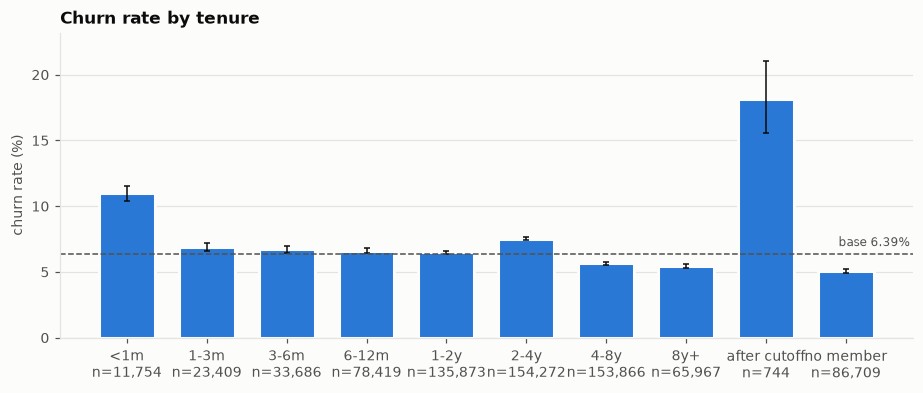

,tenure_band,n,churners,churn_rate,ci_low,ci_high,share,lift
0,<1m,11754,1291,0.1098,0.1043,0.1156,0.0158,1.7182
1,1-3m,23409,1612,0.0689,0.0657,0.0722,0.0314,1.0773
2,3-6m,33686,2267,0.0673,0.0647,0.0700,0.0452,1.0528
3,6-12m,78419,5201,0.0663,0.0646,0.0681,0.1053,1.0375
4,1-2y,135873,8807,0.0648,0.0635,0.0661,0.1825,1.0140
5,2-4y,154272,11616,0.0753,0.0740,0.0766,0.2072,1.1779
6,4-8y,153866,8705,0.0566,0.0554,0.0577,0.2066,0.8850
7,8y+,65967,3590,0.0544,0.0527,0.0562,0.0886,0.8513
8,after cutoff,744,135,0.1815,0.1554,0.2108,0.0010,2.8386
9,no member,86709,4380,0.0505,0.0491,0.0520,0.1164,0.7902


In [15]:
TEN_ORDER = ["<1m", "1-3m", "3-6m", "6-12m", "1-2y", "2-4y", "4-8y", "8y+", "after cutoff", "no member"]
t = pl.col("tenure_days")
df = df.with_columns(tenure_band=
    pl.when(t.is_null()).then(pl.lit("no member")).when(t < 0).then(pl.lit("after cutoff"))
    .when(t < 31).then(pl.lit("<1m")).when(t < 92).then(pl.lit("1-3m")).when(t < 183).then(pl.lit("3-6m"))
    .when(t < 366).then(pl.lit("6-12m")).when(t < 731).then(pl.lit("1-2y")).when(t < 1461).then(pl.lit("2-4y"))
    .when(t < 2922).then(pl.lit("4-8y")).otherwise(pl.lit("8y+")))
ten_table = C.churn_rate_by(df, "tenure_band", order=TEN_ORDER)
fig, ax = plt.subplots(figsize=(10, 3.6))
C.plot_churn_rate(ten_table, "tenure_band", ax=ax, base_rate=BASE, title="Churn rate by tenure")
C.save_fig(fig, "01_tenure_band"); plt.show()
ten_table

In [16]:
tv = C.churn_rate_by(df.filter(pl.col("via") != "no member"), ["tenure_band", "via"], order=TEN_ORDER)
tv = tv[tv["n"] >= 1000]
tv.pivot(index="tenure_band", columns="via", values="churn_rate").reindex([o for o in TEN_ORDER if o in set(tv.tenure_band)])

via,3,4,7,9
tenure_band,,,,
<1m,NaN,0.2878,0.0073,NaN
1-3m,NaN,0.2100,0.0073,0.2414
3-6m,0.1749,0.1874,0.0103,0.1726
6-12m,0.1513,0.1588,0.0346,0.1294
1-2y,0.1527,0.1741,0.0248,0.1489
2-4y,0.1245,NaN,0.0427,0.1100
4-8y,0.0976,NaN,0.0323,0.0750
8y+,NaN,NaN,NaN,0.0544


- Raw, tenure looks non-monotonic (new customers churn 11 %, then a bump at 2–4 years). Split by channel the picture is cleaner: **inside channels 3, 4 and 9 churn falls as tenure grows** (channel 9: 24 % in the first months, 5.4 % after 8 years); channel 7 is low at every tenure, and its newest customers churn least (0.7 %). The raw curve is distorted because channels were used in different years (channel 9 is almost all of the 8+ year customers).
- **744 customers have a registration date after the cutoff** (up to 2017-03-30) and churn at 18 %. `members_v3` is a later snapshot, so this date was overwritten after the cutoff: it is future information and must be treated as unknown, not as a band of its own. (The same snapshot problem may affect other member fields, which cannot be checked; it is a stated limitation.)
- Tenure and channel must be used together. A tree finds the interaction by itself; for the linear model, bands of tenure plus channel are the minimum.

In [17]:
reg_month = C.churn_rate_by(df.filter(pl.col("tenure_days") >= 366)
                            .with_columns(month=C.to_date("registration_init_time").dt.month().cast(pl.String)),
                            "month", order=[str(i) for i in range(1, 13)])
reg_month[["month", "n", "churn_rate", "ci_low", "ci_high"]]

,month,n,churn_rate,ci_low,ci_high
0,1,58680,0.0739,0.0718,0.0760
1,2,36712,0.0671,0.0646,0.0697
2,3,35863,0.0701,0.0675,0.0728
3,4,30618,0.0627,0.0600,0.0655
4,5,32240,0.0637,0.0611,0.0665
5,6,32977,0.0707,0.0680,0.0735
6,7,41966,0.0595,0.0573,0.0618
7,8,44692,0.0620,0.0598,0.0643
8,9,43242,0.0626,0.0604,0.0649
9,10,51802,0.0552,0.0533,0.0572


Registration month, restricted to customers registered more than a year ago (so it is not just "new customer"): the differences are small (5.5–7.4 %). The raw January/February bump comes from recent sign-ups, which tenure already captures. `registration_month` has no reason to stay.

## 9. What does each field add? (cross-validated)

Logistic regression on one-hot encodings, adding one block at a time, plus gradient boosting on the same inputs as a non-linear reference.

In [18]:
X = df.with_columns(pl.col("city").cast(pl.String).fill_null("no member").alias("city_s")).select(
    "via", "profile_state", "age_band", "tenure_band", "city_s").to_pandas()
steps = [
    ("via", ["via"]),
    ("+ profile_state", ["via", "profile_state"]),
    ("+ via x profile", ["via", "profile_state", "via_x_profile"]),
    ("+ age_band", ["via", "profile_state", "via_x_profile", "age_band"]),
    ("+ tenure_band", ["via", "profile_state", "via_x_profile", "age_band", "tenure_band"]),
    ("+ city", ["via", "profile_state", "via_x_profile", "age_band", "tenure_band", "city_s"]),
]
X["via_x_profile"] = X["via"] + "|" + X["profile_state"]
rows = {name: cv(logit(cat=cols), cols) for name, cols in steps}
all_cols = ["via", "profile_state", "age_band", "tenure_band", "city_s"]
rows["GBM, all fields"] = cv(gbm(all_cols, cat_cols=all_cols), all_cols)
rows["GBM, all but city"] = cv(gbm(all_cols[:-1], cat_cols=all_cols[:-1]), all_cols[:-1])
blocks = pd.DataFrame(rows).T
blocks["log_loss_gain_vs_prior"] = prior_ll - blocks["log_loss"]
blocks

,roc_auc,roc_auc_sd,log_loss,log_loss_gain_vs_prior
via,0.6801,0.0022,0.2241,0.0135
+ profile_state,0.6799,0.0022,0.2241,0.0136
+ via x profile,0.6890,0.0017,0.2232,0.0144
+ age_band,0.6968,0.0021,0.2217,0.0159
+ tenure_band,0.7034,0.0016,0.2209,0.0167
+ city,0.7057,0.0019,0.2198,0.0178
"GBM, all fields",0.7163,0.0022,0.2176,0.0201
"GBM, all but city",0.7123,0.0022,0.2188,0.0188


## 10. Conclusions


**Age.** The relationship is a threshold: churn is 19 % at 18 or younger, 15 % at 19–21, 10 % at 22–24 and about 7 % from 25 on. Mean imputation (the current w1 encoding) is the weakest option in every comparison: it puts the 49 % with unknown age (4.7 % churn) at the average age, inside the 25–29 group (7.4 %). Bands help the linear model (AUC 0.690 vs 0.687 next to channel) and a raw age with NaN for missing gives trees the same information without the distortion.

**Profile and channel.** `bd = 0`, `gender = null` and `city = 1` are one event: an empty profile. Its low churn is mostly composition, because channel 7 (3 % churn) holds 85 % of empty profiles. Profile state adds nothing next to channel on its own (AUC 0.6801 → 0.6799) but its interaction with channel does (0.689), driven by channel 9, where empty profiles churn twice as much.

**Ranking of member fields** (cross-validated, logistic): channel (0.680) ≫ channel × profile (+0.009) > age band (+0.008) > tenure band (+0.007) > city (+0.002). Gradient boosting on the same fields reaches 0.716, so non-linear interactions add a little more. Gender and registration month add nothing.

All member fields together reach an AUC of about 0.70–0.72 on their own: useful context, but well below the subscription state found in notebook 00.


In [19]:
decisions = C.write_decisions("01", "Members", [
    {"finding": "Age has a threshold shape (19 % at <=18, ~7 % from 25 on); mean imputation is the weakest encoding",
     "decision": "Replace `bd` mean + `bd_missing` by `age_band` (<=18, 19-21, 22-24, 25-29, 30-44, 45+, unknown) for the linear model; trees get `bd` with NaN for unknown (no imputation)",
     "kind": "transformation"},
    {"finding": "403 ages outside 1..100 (excluding 0)",
     "decision": "Treat as unknown (NaN / `unknown` band)",
     "kind": "cleaning"},
    {"finding": "`bd = 0`, `gender = null` and `city = 1` are the same empty-profile event (48 % of fit)",
     "decision": "New `profile_state` (complete / incomplete / no member); `city = 1` with an incomplete profile is recoded to `unknown`",
     "kind": "new feature"},
    {"finding": "Profile state alone adds nothing next to channel; channel x profile does (+0.009 AUC), driven by channel 9",
     "decision": "Linear model gets the `registered_via x profile_state` interaction; trees get both columns",
     "kind": "new feature"},
    {"finding": "Channel is the strongest member signal (3 % for 7, 18 % for 4); only 5 levels, no negatives",
     "decision": "Keep `registered_via` as categorical with `no member` level; drop the dead 'negative -> mode' rule",
     "kind": "cleaning"},
    {"finding": "Gender value: male 8.9 % vs female 8.6 %",
     "decision": "Do not use the gender value; its absence lives in `profile_state`",
     "kind": "drop"},
    {"finding": "Among complete profiles cities differ little (7-10 %) except city 1; city adds +0.002 AUC",
     "decision": "Keep `city` (after the recoding above) and group cities with < 1,000 fit customers into `other`; low priority",
     "kind": "transformation"},
    {"finding": "Tenure lowers churn inside channels 3/4/9; raw curve is distorted by channel mix",
     "decision": "Keep `tenure_days` (trees) and `tenure_band` (linear); interpret only next to channel",
     "kind": "transformation"},
    {"finding": "744 registration dates fall after the cutoff (snapshot overwritten), 18 % churn",
     "decision": "Treat their tenure as unknown (NaN), never as a band of their own",
     "kind": "cleaning"},
    {"finding": "Registration month: 5.5-7.4 % once new customers are excluded",
     "decision": "Drop `registration_month` and `registration_year` (tenure already covers them)",
     "kind": "drop"},
])
decisions

,finding,decision,kind
0,"Age has a threshold shape (19 % at <=18, ~7 % from 25 on); mean imputation is the weakest encoding","Replace `bd` mean + `bd_missing` by `age_band` (<=18, 19-21, 22-24, 25-29, 30-44, 45+, unknown) for the linear model; trees get `bd` with NaN for unknown (no imputation)",transformation
1,403 ages outside 1..100 (excluding 0),Treat as unknown (NaN / `unknown` band),cleaning
2,"`bd = 0`, `gender = null` and `city = 1` are the same empty-profile event (48 % of fit)",New `profile_state` (complete / incomplete / no member); `city = 1` with an incomplete profile is recoded to `unknown`,new feature
3,"Profile state alone adds nothing next to channel; channel x profile does (+0.009 AUC), driven by channel 9",Linear model gets the `registered_via x profile_state` interaction; trees get both columns,new feature
4,"Channel is the strongest member signal (3 % for 7, 18 % for 4); only 5 levels, no negatives",Keep `registered_via` as categorical with `no member` level; drop the dead 'negative -> mode' rule,cleaning
5,Gender value: male 8.9 % vs female 8.6 %,Do not use the gender value; its absence lives in `profile_state`,drop
6,Among complete profiles cities differ little (7-10 %) except city 1; city adds +0.002 AUC,"Keep `city` (after the recoding above) and group cities with < 1,000 fit customers into `other`; low priority",transformation
7,Tenure lowers churn inside channels 3/4/9; raw curve is distorted by channel mix,Keep `tenure_days` (trees) and `tenure_band` (linear); interpret only next to channel,transformation
8,"744 registration dates fall after the cutoff (snapshot overwritten), 18 % churn","Treat their tenure as unknown (NaN), never as a band of their own",cleaning
9,Registration month: 5.5-7.4 % once new customers are excluded,Drop `registration_month` and `registration_year` (tenure already covers them),drop


---
**Previous:** `00_population_label_coverage.ipynb` · **Next:** `02_transactions_quality.ipynb`